# IAU Projekt - fáza 3

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

In [2]:
RANDOM_SEED = 1

In [3]:
train_df = pd.read_csv("train_preprocessed.csv")
test_df = pd.read_csv("test_preprocessed.csv")

X_train, y_train = train_df.drop(columns=["failure"]), train_df["failure"]
X_test, y_test = test_df.drop(columns=["failure"]), test_df["failure"]

## 3.2 Trénovanie a vyhodnotenie klasifikátorov strojového učenia

In [4]:
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("podiel failure v train:", round(y_train.mean(), 3), "v test:", round(y_test.mean(), 3))

X_train: (11303, 10) X_test: (2826, 10)
podiel failure v train: 0.118 v test: 0.125


Naše dátá sú nevyvážené. Dáta s poruchou sa vyskytujú v iba v približne 12% pripadoch. Pokiaľ by náš model pre všetky prípady predikoval, že nedošlo k poruchu dosiahol by presnosť 88%, ale ani raz by nenašiel skutočnú poruchu. Preto pri vyhodnocovaní budeme sledovať popri **accuracy** hlavne **precision** a **recall** pre triedu `failure = 1`:
- **recall** hovorí, koľko skutočných porúch model odhalil.
- **precision** ukazuje, z koľkých predikovaných porúch boli naozajstné poruchy.

In [5]:
def evaluate(name, model): # funkcia pre vyhodnotenie modelu 
    rows = []
    for split, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        y_pred = model.predict(X)
        rows.append({
            "model": name,
            "mnozina": split,
            "accuracy": accuracy_score(y, y_pred),
            "precision": precision_score(y, y_pred, zero_division=0),
            "recall": recall_score(y, y_pred),
        })
    return pd.DataFrame(rows)

results = []

### Stromový algoritmus - DecisionTreeClassifier
Vybrali sme stromový algoritmus DecisionTreeClassifier, ktorý používa algoritmus CART. Čiže to vyzerá ako dobrá voľba na porovanie s ID3 algoritmom.

Skúsime strom natrenovať s predvolenými parametrami.

In [6]:
from sklearn.tree import DecisionTreeClassifier

tree_default = DecisionTreeClassifier(random_state=RANDOM_SEED).fit(X_train, y_train)
print("hlbka stromu:", tree_default.get_depth(), "pocet listov:", tree_default.get_n_leaves())
results.append(evaluate("DecisionTree (default)", tree_default))
results[-1].round(3)

hlbka stromu: 28 pocet listov: 1466


,model,mnozina,accuracy,precision,recall
0,DecisionTree (default),train,1.000,1.000,1.000
1,DecisionTree (default),test,0.795,0.203,0.222


Náš strom sa rozrástol do hĺbky 28 a vyprodukoval až 1466 listov. Ked sa pozrieme na metriky, tak je jasne vidno, že storm sa dokonale naučil trénovacie dáta, ale na testovacej množine už to vôbec nevyzeralo dobre: precision 0,203 a recall 0,222. Jednoznačne sa teda jedna o overfitting. 

Aby sme mali lepší model na porovnanie, tak sa pokusime znižiť overfitting nastavenim maximalnej hĺbky stromu na 5. Kedže sú naše dáta nevyvážené, tak pre porovnanie natrénujeme strom aj s parametrom `class_weight="balanced"`, ktorý dáva väčšiu váhu menšínovej triede.

In [7]:
tree_d5 = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_SEED).fit(X_train, y_train)
results.append(evaluate("DecisionTree (max_depth=5)", tree_d5))

tree_bal = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_SEED).fit(X_train, y_train)
results.append(evaluate("DecisionTree (max_depth=5, balanced)", tree_bal))

pd.concat(results[-2:]).round(3)

,model,mnozina,accuracy,precision,recall
0,DecisionTree (max_depth=5),train,0.884,0.580,0.084
1,DecisionTree (max_depth=5),test,0.873,0.413,0.054
0,"DecisionTree (max_depth=5, balanced)",train,0.689,0.220,0.641
1,"DecisionTree (max_depth=5, balanced)",test,0.665,0.205,0.588


Strom s maximalnou hĺbkou 5 už neoverfituje no recall má len 0.054. Zachytí približne 5% poruch. Ked ho porovnáme s modelom kde sme nastavili `class_weight="balanced"` tak tu už recall stúpol na 0.588 čiže náš model zachytí približne 59% porúch. Accuracy klesla na 0.665, pretože model teraz častejšie označí aj záznam bez poruchy ako poruchu a precision je 0.205.

### Nestromový algoritmus - Logistická regresia
Ako nestromový algoritmus sme si vybrali **logistickú regresiu**.

Rovnako ako pri strome skúsime verziu bez vyváženia tried a s `class_weight="balanced"`.

In [8]:
logreg = LogisticRegression().fit(X_train, y_train)
results.append(evaluate("LogisticRegression", logreg))

logreg_bal = LogisticRegression(class_weight="balanced").fit(X_train, y_train)
results.append(evaluate("LogisticRegression (balanced)", logreg_bal))

pd.concat(results[-2:]).round(3)

,model,mnozina,accuracy,precision,recall
0,LogisticRegression,train,0.884,0.729,0.026
1,LogisticRegression,test,0.879,0.867,0.037
0,LogisticRegression (balanced),train,0.664,0.212,0.676
1,LogisticRegression (balanced),test,0.655,0.214,0.659


Logistická regresia sa správa rovnako ako strom. Bez vyváženia tried predikuje poruchu len výnimočne: precision je síce 0.867, ale recall iba 0.037, takže zachití iba zlomok porúch.  S `class_weight="balanced"` dosahuje recall **0.659** pri precision 0.214, čo je o niečo lepšie ako Decission tree s `class_weight="balanced"`.

Keď porovname metriky na trénovacej a testovacej množine, tak sú takmer rovnake, čiže ná model neoverfituje.

Ďalej porovnávame už len vyvážené verzie modelov.

### Matice zámen
Pre vyzualizáciu počtu zachytených a nezachytených porúch si na testovacej množine vykreslíme maticu zámen pre Decission tree a Logistickú regresiu.

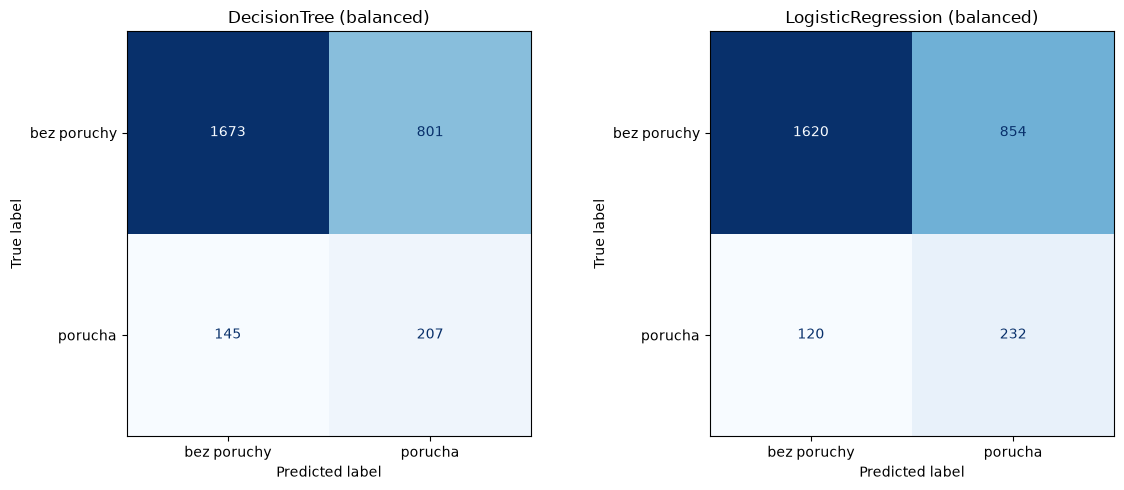

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axs, [("DecisionTree (balanced)", tree_bal), ("LogisticRegression (balanced)", logreg_bal)]):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["bez poruchy", "porucha"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
plt.show()

Z 352 porúch zachití Decission tree 207 a Logistická regresia 232. Oba modeli majú celkom veľa false positive. Modely majú precision iba okolo 0.2, čiže poruchy sa oddeľujú od bežnej prevádzky len slabo.

### Vizualizácia natrénovaných pravidiel

Vizualizujeme si natrenované pravidlá DecissionTreeClassifier pomocout `plot_tree`. Pre čitateľnosť zobrazíme len prvé 2 úrovne stromu.

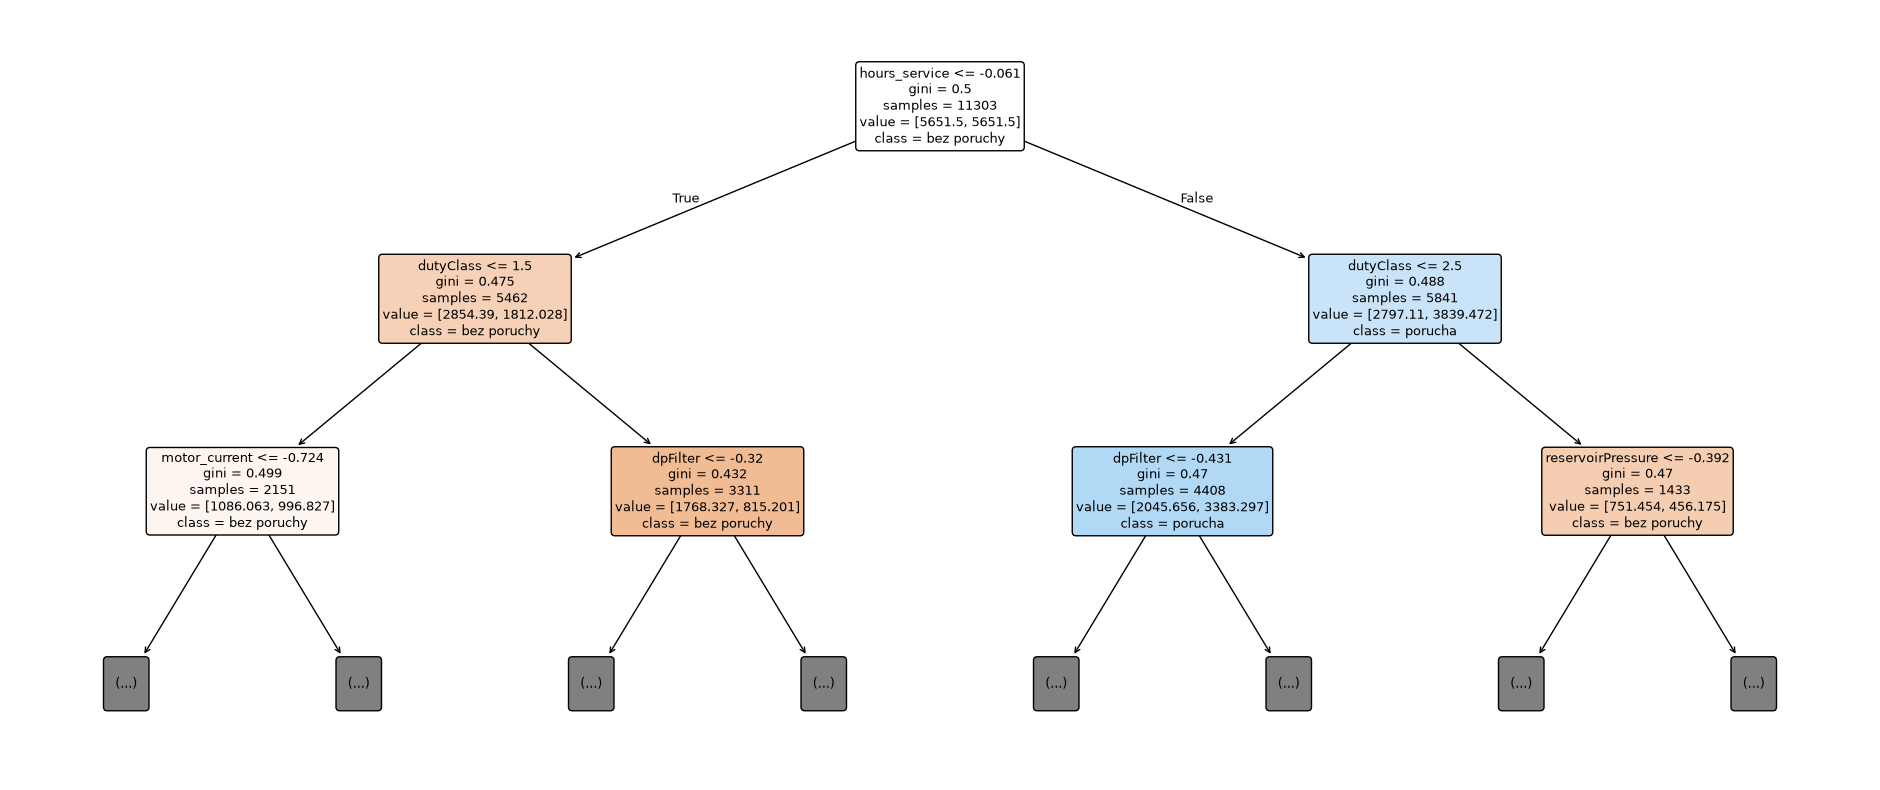

In [10]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(tree_bal, feature_names=X_train.columns, class_names=["bez poruchy", "porucha"], filled=True, rounded=True, max_depth=2, fontsize=9, ax=ax)
plt.show()

Na začiatku sa strom delí podľa `hours_service` čo dáva aj zmysel keďže jednotky s večším počtom odpracovaných hodín môžu mať väčšiu pravdepodobnosť poruchy. Celkom zaujmavé je že vyšia dutyClass vedie skôr k triede bez poruchy. 

Pri logistickej regresii si vieme vizualizovať koeficienty modelu. Kladný koeficient zvyšuje pravdepodobnosť poruchy, záporný ju zase znižuje.

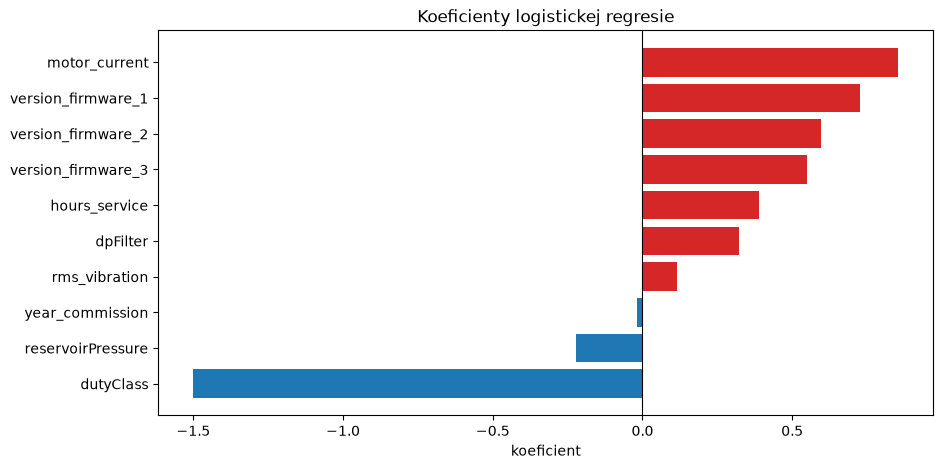

In [11]:
coefs = pd.Series(logreg_bal.coef_[0], index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(coefs.index, coefs.values, color=["tab:red" if c > 0 else "tab:blue" for c in coefs.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Koeficienty logistickej regresie")
ax.set_xlabel("koeficient")
plt.show()

### Porovnanie modelov a porovnanie s ID3

Pre porovnanie výsldky všetkých modelov (accuracy, precision, recall) spojíme do jednej tabuľky (TODO: Mato pridaj ID3 do porovnania)

In [12]:

comparison = pd.concat(results, ignore_index=True)
(comparison
    .pivot(index="model", columns="mnozina", values=["accuracy", "precision", "recall"])
    .reindex(index=comparison["model"].unique())
    .reindex(columns=["train", "test"], level=1) 
    .round(3))

accuracy        precision        recall  \
mnozina                                 train   test     train   test  train   
model                                                                          
DecisionTree (default)                  1.000  0.795     1.000  0.203  1.000   
DecisionTree (max_depth=5)              0.884  0.873     0.580  0.413  0.084   
DecisionTree (max_depth=5, balanced)    0.689  0.665     0.220  0.205  0.641   
LogisticRegression                      0.884  0.879     0.729  0.867  0.026   
LogisticRegression (balanced)           0.664  0.655     0.212  0.214  0.676   

                                             
mnozina                                test  
model                                        
DecisionTree (default)                0.222  
DecisionTree (max_depth=5)            0.054  
DecisionTree (max_depth=5, balanced)  0.588  
LogisticRegression                    0.037  
LogisticRegression (balanced)         0.659

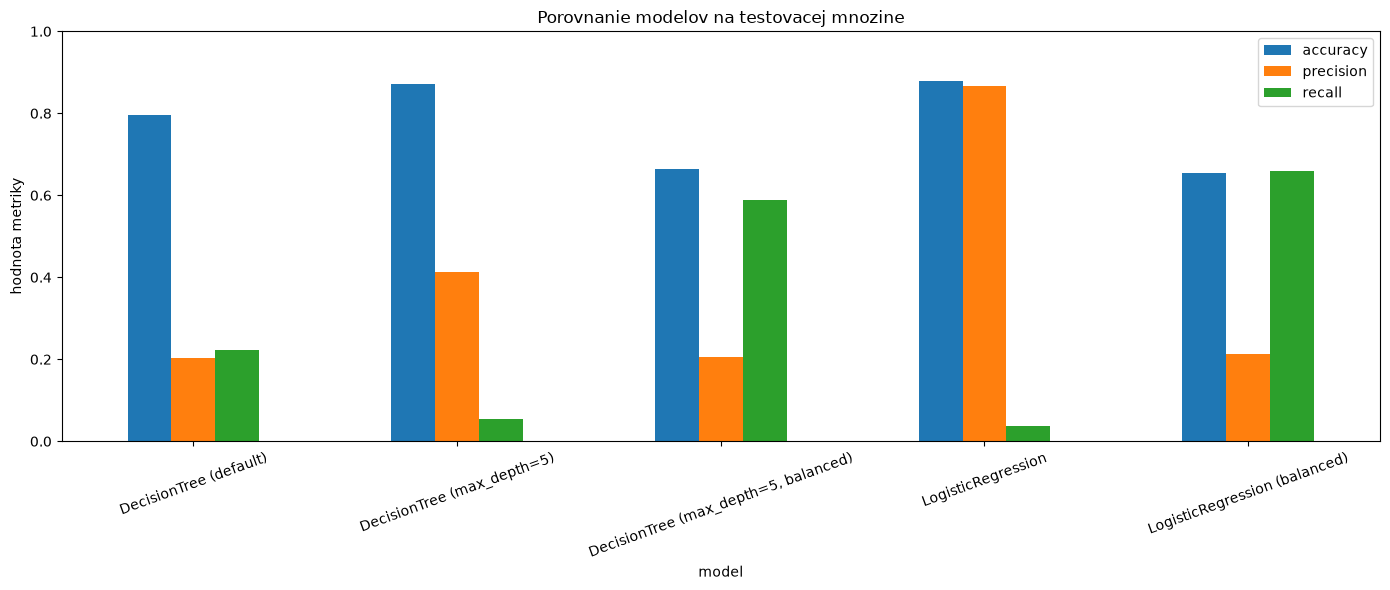

In [13]:
test_results = comparison[comparison["mnozina"] == "test"].set_index("model")[["accuracy", "precision", "recall"]]

test_results.plot(kind="bar", figsize=(14, 6), rot=20)
plt.title("Porovnanie modelov na testovacej mnozine")
plt.ylabel("hodnota metriky")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

### Zhrnutie 3.2
- **Stromový model (`DecisionTreeClassifier`)** bez obmedzenia hlbky overfitoval, Po obmedzení hĺbky a vyvážení tried dosahuje na testovacej množine recall 0.588 a precision 0.205 bez overfitu.
- **Nestromový model (`LogisticRegression`)** model s vyvažením tired je o niečo lepši od DecissionTreeClassifier s vyvážením tried. Na testovacej množine dosahuje recall 0.659 a precision 0.214. Train a test metriky sú takmer rovnaké, čiže model neoverfituje.
- **Porovnanie s ID3:** (TODO: Mato)

### Uprava fázy 2

Nadpadlo nám ešte skontrolovať či nahradením chýbajúcich hodnôt pomocou KNN imputeru neprišli o informáciu o tom že tam hodnota chýbala. 

In [14]:

readings = pd.read_csv("readings.csv", delimiter="\t").drop_duplicates()
readings["id_unit"] = readings["id_unit"].str.replace("U", "").astype(int)
units = pd.read_csv("units.csv")
df = readings.merge(units[["id_unit", "hours_service"]], on="id_unit", how="inner")
df["temperature_oil"] = df["temperature_oil"].replace(-999, np.nan)
df["motor_current"] = df["motor_current"].replace(99, np.nan)

missing_cols = [col for col in df.columns if df[col].isna().any()]
pd.DataFrame({
    "pocet chybajucich": df[missing_cols].isna().sum(),
    "failure ked chyba atribúť": [df.loc[df[col].isna(), "failure"].mean() for col in missing_cols],
    "failure ked je nechýba atribúť": [df.loc[df[col].notna(), "failure"].mean() for col in missing_cols],
}).round(3)

,pocet chybajucich,failure ked chyba atribúť,failure ked je nechýba atribúť
motor_current,16,0.062,0.120
dpFilter,539,0.553,0.102
temperature_oil,38,0.211,0.119
rms_vibration,554,0.534,0.103
humidityIntake,681,0.104,0.120
hours_service,728,0.109,0.120


Z tabuľky vyššie je vidieť, že keď chýba `dpFilter` alebo `rms_vibration`, ide až v viac ako 50% prípadov o poruchu, a pri nameranich hodnotách len v 10 %. KNN imputer vo fáze 2 tieto hodnoty doplnil podľa susedov a túto informáciu sme tak stratili.

Znova teda vytvoríme dáta s tým že KNN imputeru pridáme `add_indicator=True`. Imputer potom pre každý atribút s chýbajúcimi hodnotami pridá nový stĺpec s informáciou či hodnota chýbala.

In [15]:
import category_encoders as ce
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, PowerTransformer
from sklearn.impute import KNNImputer

readings_df = pd.read_csv("readings.csv", delimiter="\t", parse_dates=["ts_cycle"], date_format="mixed")
readings_df["id_unit"] = readings_df["id_unit"].str.replace("U", "").astype(int)
readings_df = readings_df.drop_duplicates().drop(columns=["ts_cycle"])

units_df = pd.read_csv("units.csv", delimiter=",")
units_df["dutyClass"] = units_df["dutyClass"].str.strip()
units_df = units_df.replace({
    "1": "light", "L": "light",
    "N": "medium", "2": "medium", "normal": "medium", "med": "medium",
    "3": "heavy", "H": "heavy"
})

gateways_df = pd.read_csv("gateways.csv", delimiter=";")
gateways_df = gateways_df.dropna(subset="id_unit")
gateways_df["id_unit"] = gateways_df["id_unit"].astype(int)

main_df = (
    readings_df
    .merge(units_df[["id_unit", "year_commission", "dutyClass", "hours_service"]], on="id_unit", how="inner", validate="many_to_one")
    .merge(gateways_df[["id_unit", "version_firmware"]], on="id_unit", how="inner", validate="many_to_one")
)
for col, code in {"temperature_oil": -999, "motor_current": 99}.items():
    main_df[col] = main_df[col].replace(code, np.nan)

X_raw = main_df.drop(columns=["failure", "id_unit"])
y_raw = main_df["failure"]
X_raw_train, X_raw_test, y_raw_train, y_raw_test = sklearn.model_selection.train_test_split(X_raw, y_raw, test_size=0.2, random_state=RANDOM_SEED)

CATEGORICAL_COLS = ["dutyClass", "version_firmware"]
NUMERIC_COLS = [col for col in X_raw.columns if col not in CATEGORICAL_COLS]
mapping = [{"col": "dutyClass", "mapping": {"light": 1, "medium": 2, "heavy": 3}}]

x = Pipeline([
    ("ordinal", ce.OrdinalEncoder(cols=["dutyClass"], mapping=mapping)),
    ("onehot", ce.OneHotEncoder(cols=["version_firmware"])),
    ("scale", ColumnTransformer([("robust", RobustScaler(), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
    ("impute", KNNImputer(n_neighbors=5, add_indicator=True)),
    ("power", ColumnTransformer([("yeo_johnson", PowerTransformer(method="yeo-johnson"), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
]).set_output(transform="pandas").fit_transform(X_raw_train)
print("pocet atributov:", x.shape[1])
print("nove stlpce:", [col for col in x.columns if col.startswith("missingindicator_")])

pocet atributov: 20
nove stlpce: ['missingindicator_motor_current', 'missingindicator_dpFilter', 'missingindicator_temperature_oil', 'missingindicator_rms_vibration', 'missingindicator_humidityIntake', 'missingindicator_hours_service']


Výber atribútov úplne rovnako ako vo fáze 2, len sme odstránili podmienku, že keď je zvolený jeden atribúť version_firmware, tak musia byť zvolené všetky version_firmware.

In [16]:
from sklearn.feature_selection import mutual_info_classif, RFE, SelectFromModel
from sklearn.ensemble import RandomForestClassifier

mic_out = pd.Series(mutual_info_classif(x, y_raw_train, random_state=0), index=x.columns)
rfe_out = pd.Series(RFE(LogisticRegression(class_weight="balanced"), n_features_to_select=1, step=1).fit(x, y_raw_train).ranking_, index=x.columns)
rfc_out = pd.Series(RandomForestClassifier(random_state=0).fit(x, y_raw_train).feature_importances_, index=x.columns)
sfm_lr_out = pd.Series(SelectFromModel(estimator=LogisticRegression()).fit(x, y_raw_train).estimator_.coef_[0], index=x.columns).abs()

results_v2 = pd.DataFrame({
    "Mutual Info": mic_out.rank(ascending=False, method="min").astype(int),
    "RFE+LogisticReg": rfe_out,
    "Random Forest": rfc_out.rank(ascending=False, method="min").astype(int),
    "SFM+LogisticReg": sfm_lr_out.rank(ascending=False, method="min").astype(int),
})
results_v2["sum points"] = results_v2.sum(axis=1)
results_v2["final order"] = results_v2["sum points"].rank(method="min").astype(int)

def select_features(max_rank):  # prvych max_rank atributov podla finalneho poradia (max_rank = maximalny pocet atributov)
    return results_v2.sort_values("final order", kind="stable").index[:max_rank].tolist()

MAX_RANK = 9
SELECTED_FEATURES_V2 = select_features(MAX_RANK)

results_v2["vybrany teraz"] = results_v2.index.isin(SELECTED_FEATURES_V2)
results_v2["vybrany vo faze 2"] = results_v2.index.isin(X_train.columns)
results_v2.sort_values("final order")

,Mutual Info,RFE+LogisticReg,Random Forest,SFM+LogisticReg,sum points,final order,vybrany teraz,vybrany vo faze 2
missingindicator_dpFilter,1,1,10,1,13,1,True,False
motor_current,6,4,1,4,15,2,True,True
missingindicator_rms_vibration,2,2,11,2,17,3,True,False
dutyClass,4,3,13,3,23,4,True,True
hours_service,3,9,5,7,24,5,True,True
dpFilter,8,10,2,6,26,6,True,True
Flowmeter,10,12,7,9,38,7,True,False
reservoirPressure,17,11,4,8,40,8,True,True
year_commission,5,13,12,11,41,9,True,True
version_firmware_2,7,6,14,15,42,10,False,True


Indikátory `missingindicator_dpFilter` a `missingindicator_rms_vibration` sa dostali na 1. a 3. miesto čiže vyzera, že nesú dôležitú informáciu tak ako sme predpokladali.

Čize zmeny oproti fáze 2 vyzerajú nasledovne:
 - Pribudli `missingindicator_dpFilter` a `missingindicator_rms_vibration`
 - vypadol `rms_vibration`
 - a vypadli všetky `version_firmware` kedže najlepší z nich už klesol na 10. miesto.

Spolu máme teda 9 atribútov namiesto 10.

Vytvoríme pipline už aj s výberom atribútov. Funkcia `prepare_data(features)` zo surových dát pripraví trénovacie a testovacie dáta s atribútmi zo zoznamu `features`. Zoznam môžeme získať cez `select_features(max_rank)`, alebo zadať vlastný:
- `prepare_data(select_features(5))` - prvých 5 atribútov podľa finálneho poradia (`max_rank` je maximálny počet atribútov),
- `prepare_data(["motor_current", "dutyClass", "missingindicator_dpFilter"])` - vlastný zoznam atribútov.

In [17]:
def prepare_data(features):  # zo surovych dat pripravi trenovacie a testovacie data s atributmi zo zoznamu features
    unknown = [col for col in features if col not in x.columns]
    if unknown:
        raise ValueError(f"nezname atributy: {unknown}, dostupne su: {list(x.columns)}")

    preprocessing = Pipeline([
        ("ordinal", ce.OrdinalEncoder(cols=["dutyClass"], mapping=mapping)),
        ("onehot", ce.OneHotEncoder(cols=["version_firmware"])),
        ("scale", ColumnTransformer([("robust", RobustScaler(), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
        ("impute", KNNImputer(n_neighbors=5, add_indicator=True)),
        ("power", ColumnTransformer([("yeo_johnson", PowerTransformer(method="yeo-johnson"), NUMERIC_COLS)], remainder="passthrough", verbose_feature_names_out=False)),
        ("select", ColumnTransformer([("selected", "passthrough", list(features))], remainder="drop", verbose_feature_names_out=False)),
    ]).set_output(transform="pandas")

    X_train_prepared = preprocessing.fit_transform(X_raw_train)
    X_test_prepared = preprocessing.transform(X_raw_test)
    return X_train_prepared, X_test_prepared, preprocessing

X_train_v2, X_test_v2, preprocessing_v2 = prepare_data(SELECTED_FEATURES_V2)
print("X_train_v2:", X_train_v2.shape, "X_test_v2:", X_test_v2.shape)

X_train_v2: (11303, 9) X_test_v2: (2826, 9)


### 3.2 na nových dátach
Natrenujeme pre porovnanie rovnaké modely ako v 3.2

In [18]:
def evaluate_v2(name, model):
    rows = []
    for split, X, y in [("train", X_train_v2, y_raw_train), ("test", X_test_v2, y_raw_test)]:
        y_pred = model.predict(X)
        rows.append({
            "model": name,
            "mnozina": split,
            "accuracy": accuracy_score(y, y_pred),
            "precision": precision_score(y, y_pred, zero_division=0),
            "recall": recall_score(y, y_pred),
        })
    return pd.DataFrame(rows)

models_v2 = {
    "DecisionTree (default)": DecisionTreeClassifier(random_state=RANDOM_SEED),
    "DecisionTree (max_depth=5)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_SEED),
    "DecisionTree (max_depth=5, balanced)": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_SEED),
    "LogisticRegression": LogisticRegression(),
    "LogisticRegression (balanced)": LogisticRegression(class_weight="balanced"),
}
comparison_v2 = pd.concat([evaluate_v2(name, model.fit(X_train_v2, y_raw_train)) for name, model in models_v2.items()], ignore_index=True)

(comparison_v2.pivot(index="model", columns="mnozina", values=["accuracy", "precision", "recall"])
              .reindex(index=comparison_v2["model"].unique())
              .reindex(columns=["train", "test"], level=1)
              .round(3))

accuracy        precision        recall  \
mnozina                                 train   test     train   test  train   
model                                                                          
DecisionTree (default)                  1.000  0.812     1.000  0.264  1.000   
DecisionTree (max_depth=5)              0.896  0.887     0.661  0.629  0.250   
DecisionTree (max_depth=5, balanced)    0.822  0.812     0.339  0.336  0.528   
LogisticRegression                      0.896  0.897     0.694  0.796  0.224   
LogisticRegression (balanced)           0.753  0.752     0.277  0.291  0.674   

                                             
mnozina                                test  
model                                        
DecisionTree (default)                0.284  
DecisionTree (max_depth=5)            0.222  
DecisionTree (max_depth=5, balanced)  0.517  
LogisticRegression                    0.233  
LogisticRegression (balanced)         0.693

Porovnanie dát z fázy 2 a z nových dát, ktoré obsahujú indikátory chýbajúcich hodnôt:

In [19]:
metrics = ["accuracy", "precision", "recall"]
old_test = comparison[comparison["mnozina"] == "test"].set_index("model")[metrics]
new_test = comparison_v2[comparison_v2["mnozina"] == "test"].set_index("model")[metrics].reindex(old_test.index)
pd.concat({"faza 2": old_test, "s indikatorom": new_test, "rozdiel": new_test - old_test}, axis=1).round(3)

faza 2                  s indikatorom  \
                                     accuracy precision recall      accuracy   
model                                                                          
DecisionTree (default)                  0.795     0.203  0.222         0.812   
DecisionTree (max_depth=5)              0.873     0.413  0.054         0.887   
DecisionTree (max_depth=5, balanced)    0.665     0.205  0.588         0.812   
LogisticRegression                      0.879     0.867  0.037         0.897   
LogisticRegression (balanced)           0.655     0.214  0.659         0.752   

                                                       rozdiel            \
                                     precision recall accuracy precision   
model                                                                      
DecisionTree (default)                   0.264  0.284    0.017     0.061   
DecisionTree (max_depth=5)               0.629  0.222    0.014     0.216   
DecisionTree (max_depth=5, balanced)     0.336  0.517    0.147     0.130   
LogisticRegression                       0.796  0.233    0.018    -0.071   
LogisticRegression (balanced)            0.291  0.693    0.096     0.078   

                                             
                                     recall  
model                                        
DecisionTree (default)                0.063  
DecisionTree (max_depth=5)            0.168  
DecisionTree (max_depth=5, balanced) -0.071  
LogisticRegression                    0.196  
LogisticRegression (balanced)         0.034

Pridanie indikátora chýbajúcich hodnôt do predspracovania teda modelom pomohlo.

### Logistická regresia podľa počtu atribútov

Skúsime natrénovať logistickú regresiu s rôznym počtom atribútov od 1 po 15. Pre porovnanie to spravíme s vyvážením tried aj bez.

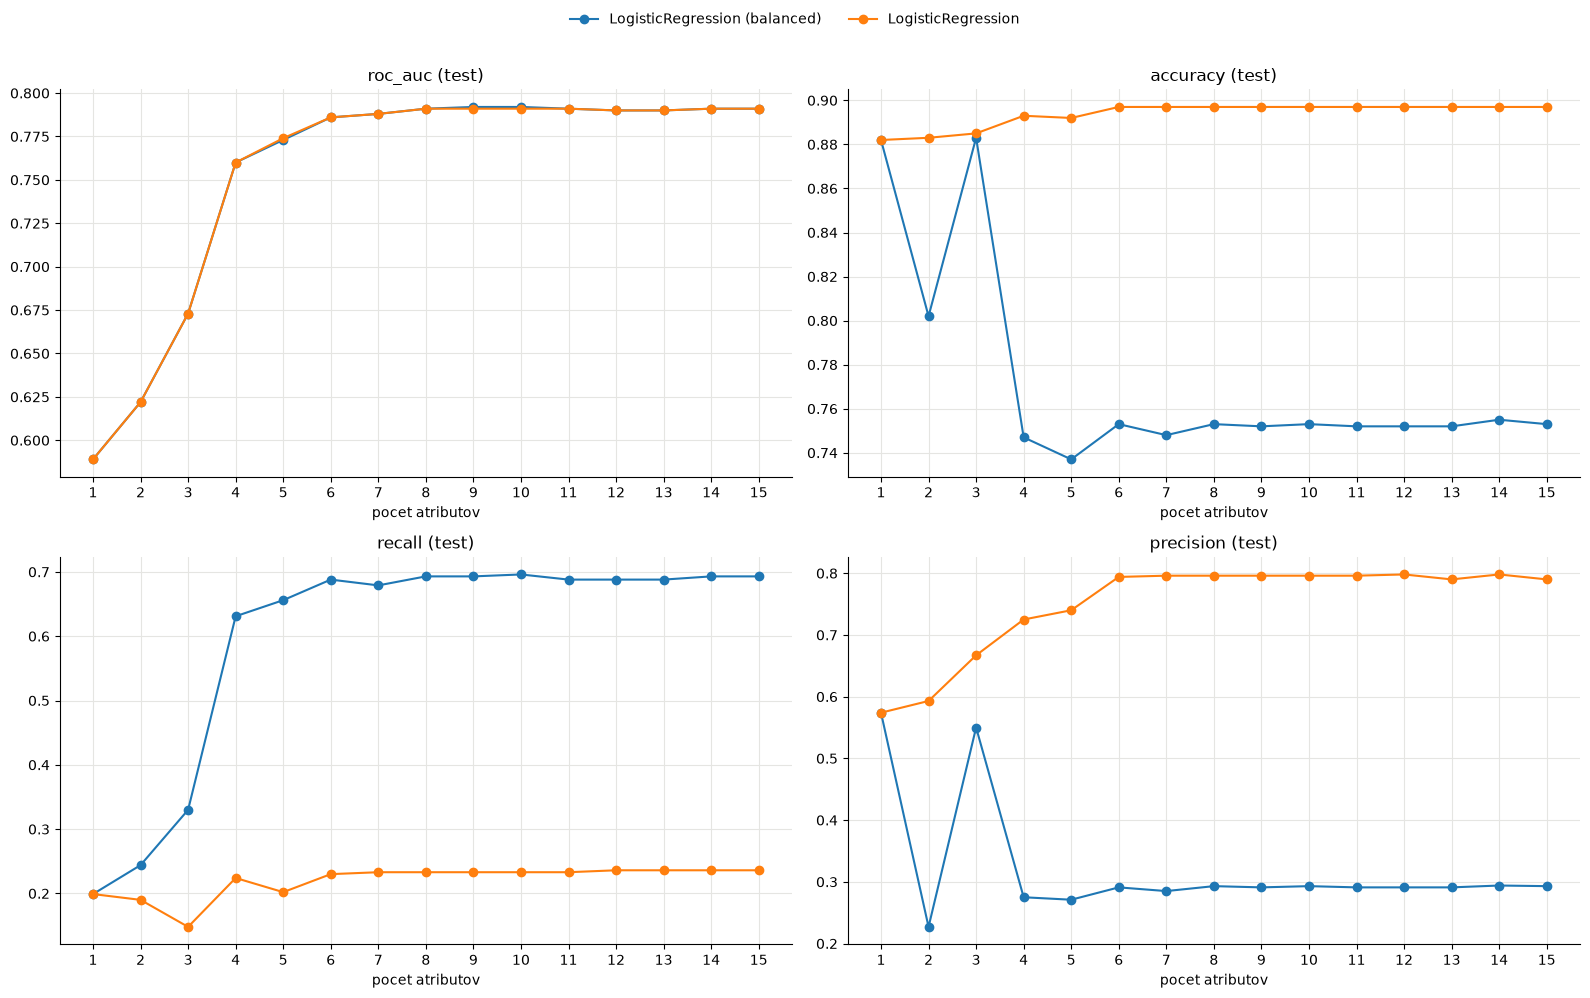

In [20]:
from sklearn.metrics import roc_auc_score

lr_models = {
    "LogisticRegression (balanced)": LogisticRegression(class_weight="balanced"),
    "LogisticRegression": LogisticRegression(),
}
rows = []
for k in range(1, 16):
    X_tr, X_te, _ = prepare_data(select_features(k))
    for model_name, model in lr_models.items():
        model.fit(X_tr, y_raw_train)
        y_pred = model.predict(X_te)
        rows.append({
            "model": model_name,
            "pocet atributov": k,
            "roc_auc": round(roc_auc_score(y_raw_test, model.predict_proba(X_te)[:, 1]), 3),
            "accuracy": round(accuracy_score(y_raw_test, y_pred), 3),
            "recall": round(recall_score(y_raw_test, y_pred), 3),
            "precision": round(precision_score(y_raw_test, y_pred, zero_division=0), 3),
        })
lr_k = pd.DataFrame(rows)

fig, axs = plt.subplots(2, 2, figsize=(16, 10))
for ax, metric in zip(axs.ravel(), ["roc_auc", "accuracy", "recall", "precision"]):
    for model_name, group in lr_k.groupby("model", sort=False):
        ax.plot(group["pocet atributov"], group[metric], marker="o", label=model_name)
    ax.set_title(f"{metric} (test)")
    ax.set_xlabel("pocet atributov")
    ax.set_xticks(range(1, 16))
    ax.grid(color="#e5e5e2", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [21]:
(lr_k.pivot(index="pocet atributov", columns="model", values=["roc_auc", "accuracy", "recall", "precision"])
     .reindex(columns=list(lr_models), level=1))

roc_auc                     \
model           LogisticRegression (balanced) LogisticRegression   
pocet atributov                                                    
1                                       0.589              0.589   
2                                       0.622              0.622   
3                                       0.673              0.673   
4                                       0.760              0.760   
5                                       0.773              0.774   
6                                       0.786              0.786   
7                                       0.788              0.788   
8                                       0.791              0.791   
9                                       0.792              0.791   
10                                      0.792              0.791   
11                                      0.791              0.791   
12                                      0.790              0.790   
13                                      0.790              0.790   
14                                      0.791              0.791   
15                                      0.791              0.791   

                                     accuracy                     \
model           LogisticRegression (balanced) LogisticRegression   
pocet atributov                                                    
1                                       0.882              0.882   
2                                       0.802              0.883   
3                                       0.883              0.885   
4                                       0.747              0.893   
5                                       0.737              0.892   
6                                       0.753              0.897   
7                                       0.748              0.897   
8                                       0.753              0.897   
9                                       0.752              0.897   
10                                      0.753              0.897   
11                                      0.752              0.897   
12                                      0.752              0.897   
13                                      0.752              0.897   
14                                      0.755              0.897   
15                                      0.753              0.897   

                                       recall                     \
model           LogisticRegression (balanced) LogisticRegression   
pocet atributov                                                    
1                                       0.199              0.199   
2                                       0.244              0.190   
3                                       0.330              0.148   
4                                       0.631              0.224   
5                                       0.656              0.202   
6                                       0.688              0.230   
7                                       0.679              0.233   
8                                       0.693              0.233   
9                                       0.693              0.233   
10                                      0.696              0.233   
11                                      0.688              0.233   
12                                      0.688              0.236   
13                                      0.688              0.236   
14                                      0.693              0.236   
15                                      0.693              0.236   

                                    precision                     
model           LogisticRegression (balanced) LogisticRegression  
pocet atributov                                                   
1                                       0.574              0.574  
2                                       0.227              0.593  
3                           

ROC AIC rastie približne do 8 atribútov a potom uz ostáva rovnaké. Ostatné vyhodnocovacie metriky sa tiež už po 8 atribútoch moc nemenia. 